# 10 — Statistical Power Planning
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 4 (Pilot Quality Audit & Statistical Power Planning)  
**Objective:** Visualize statistical power curves for McNemar's paired test and compute the required benchmark sample size scaling under oracle admission yield.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
power_file = os.path.join(repo_root, "results", "power_analysis_report.json")
with open(power_file) as f:
    power_data = json.load(f)

summary = power_data["regime_summary"]
print("Power Analysis Summary (Alpha = 0.05, Target Power = 0.80):")
print("-" * 85)
for s in summary:
    print(f"{s['name']:<18} | Delta: {s['delta_recovery']:<5.2f} | Req Pairs: {s['required_matched_pairs_binary']:<4} | Oracle Yield: {s['oracle_admission_yield']*100:.0f}% | Raw Rollouts: {s['required_raw_candidate_rollouts']}")
print("-" * 85)


Power Analysis Summary (Alpha = 0.05, Target Power = 0.80):
-------------------------------------------------------------------------------------
Small Effect Size  | Delta: 0.05  | Req Pairs: 783  | Oracle Yield: 20% | Raw Rollouts: 3915
Medium Effect Size | Delta: 0.15  | Req Pairs: 120  | Oracle Yield: 20% | Raw Rollouts: 600
Large Effect Size  | Delta: 0.30  | Req Pairs: 37   | Oracle Yield: 20% | Raw Rollouts: 185
-------------------------------------------------------------------------------------


## 1. Power Curves vs Sample Size (Matched Pairs)
We plot the statistical power achieved as a function of matched sample size $N$ across effect size regimes.

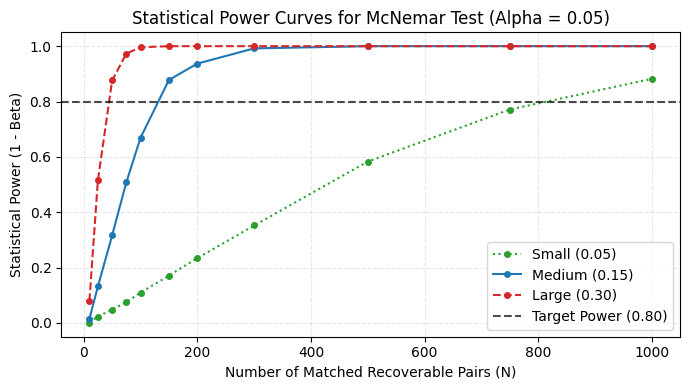

In [2]:
curves = power_data["power_curves"]

fig, ax = plt.subplots(figsize=(7, 4))
styles = {"small": ("#2ca02c", ":", "Small (0.05)"), "medium": ("#1f77b4", "-", "Medium (0.15)"), "large": ("#d62728", "--", "Large (0.30)")}

for reg, (color, ls, label) in styles.items():
    xs = [pt["n_pairs"] for pt in curves[reg]]
    ys = [pt["power"] for pt in curves[reg]]
    ax.plot(xs, ys, color=color, linestyle=ls, marker="o", markersize=4, label=label)

ax.axhline(0.80, color="black", linestyle="--", alpha=0.7, label="Target Power (0.80)")
ax.set_xlabel("Number of Matched Recoverable Pairs (N)")
ax.set_ylabel("Statistical Power (1 - Beta)")
ax.set_title("Statistical Power Curves for McNemar Test (Alpha = 0.05)")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()
plt.show()


## 2. Benchmark Scale Recommendation
We inspect the formal recommendation for the Phase 5/6 benchmark design.

In [3]:
rec = power_data["recommendations"]
print("Recommended Benchmark Configuration:")
print(f" - Target Matched Pairs per Policy: {rec['minimum_viable_benchmark_pairs']}")
print(f" - Raw Candidate Rollouts needed:   {rec['minimum_raw_rollouts_per_policy']}")
print(f" - Evaluation Seeds:                {rec['recommended_seeds']}")
print(f" - Detectable Effect Size:          Delta >= {rec['target_detectable_effect_size']}")
print(f" - Justification:                   {rec['justification']}")


Recommended Benchmark Configuration:
 - Target Matched Pairs per Policy: 100
 - Raw Candidate Rollouts needed:   500
 - Evaluation Seeds:                50
 - Detectable Effect Size:          Delta >= 0.15
 - Justification:                   With N=100 admitted matched pairs, the benchmark achieves >80% power to detect a medium effect size (Delta >= 0.15) at alpha=0.05. Given a 20% oracle admission rate, generating 500 candidate failure rollouts per policy across 50 seeds ensures statistical adequacy.
